# SIMPLE LINEAR REGRESSION MODEL

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

## Load the data

In [27]:
from sqlalchemy import create_engine
engine = create_engine("postgresql+psycopg2://postgres@localhost:5432/postgres")


In [28]:
adv = pd.read_csv('advertising.csv')
adv.to_sql("advertising", engine, if_exists="replace", index=False)
adv.head()
adv.info()
adv.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


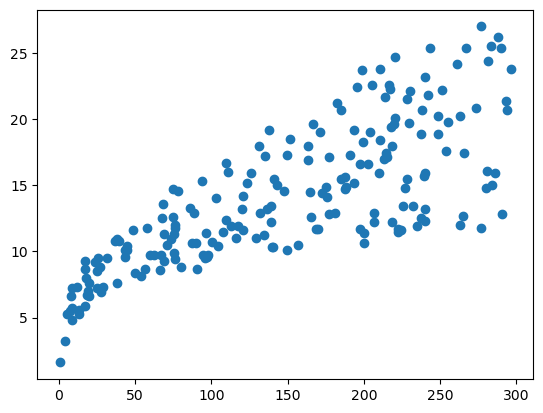

In [29]:
plt.scatter(adv['TV'], adv['sales'])

In [136]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = adv[['TV']]
y = adv['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [137]:
print(model.intercept_)
print(model.coef_)

7.119638430592953
[0.04652973]


In [117]:
y_pred = model.predict(X_test)

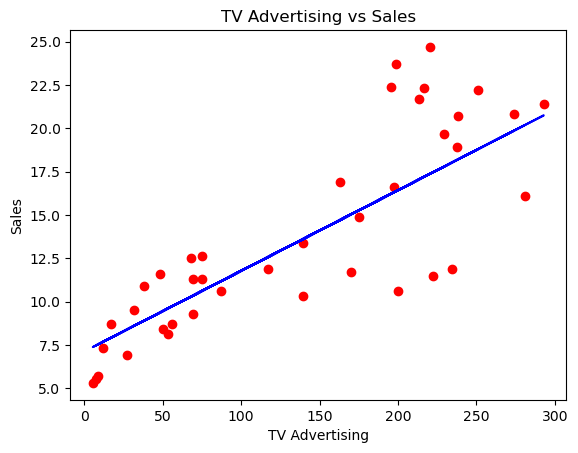

In [118]:
plt.scatter(X_test, y_test, color='red')
plt.plot(X_test, model.predict(X_test), color='blue')
plt.title('TV Advertising vs Sales')
plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.show()


In [119]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

print(np.sqrt(mean_squared_error(y_test, y_pred)))
print(r2_score(y_test, y_pred))
print(mean_absolute_error(y_test, y_pred))

3.194472431998898
0.6766954295627076
2.444420003751042


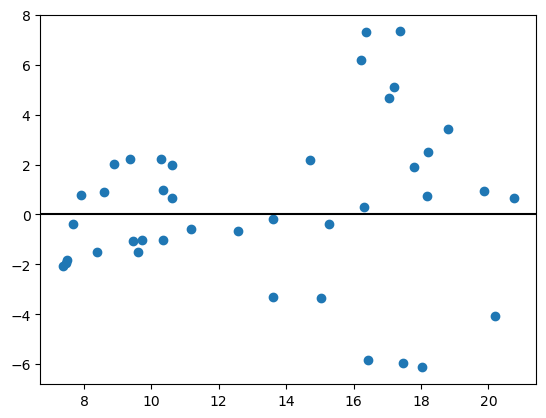

In [120]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color="black")

In [123]:
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB
from sklearn.metrics import mean_absolute_error

row = pd.DataFrame([{
    "project": "p1_advertising",
    "model": "slr_TV",
    "params": {"feature": "TV", "test_size": 0.2, "random_state": 42},
    "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "mae": float(mean_absolute_error(y_test, y_pred)),
    "r2": float(r2_score(y_test, y_pred)),
    "slope": float(model.coef_[0]),
    "run_at": datetime.now(),
}])
row.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

In [122]:
from sqlalchemy import text
with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS model_results"))

In [134]:
pd.read_sql("select * from model_results", engine)

,project,model,params,rmse,mae,r2,slope,run_at
0,p1_advertising,slr_TV,"{'feature': 'TV', 'test_size': 0.2, 'random_st...",3.194472,2.444420,0.676695,0.046530,2026-10-20 10:07:57.859605
1,p1_advertising,slr_radio,"{'feature': 'radio', 'test_size': 0.2, 'random...",4.821697,3.929879,0.263431,0.204407,2026-10-20 10:08:16.971084
2,p1_advertising,slr_newspaper,"{'feature': 'newspaper', 'test_size': 0.2, 'ra...",5.533600,4.782194,0.029872,0.059757,2026-10-20 10:08:47.503287


## Radio

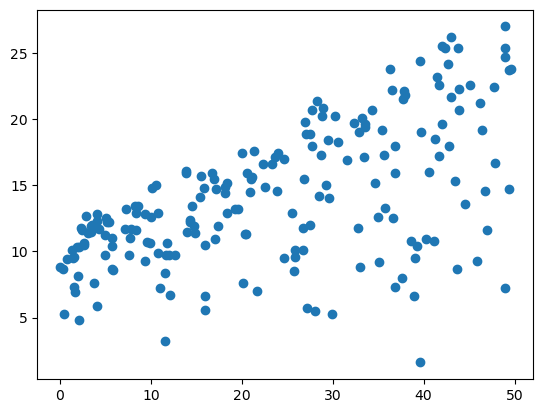

In [97]:
plt.scatter(adv['radio'], adv['sales'])

In [138]:
X = adv[['radio']]
y = adv['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [139]:
print(model.intercept_)
print(model.coef_)

9.424065649663842
[0.20440685]


In [126]:
y_pred = model.predict(X_test)

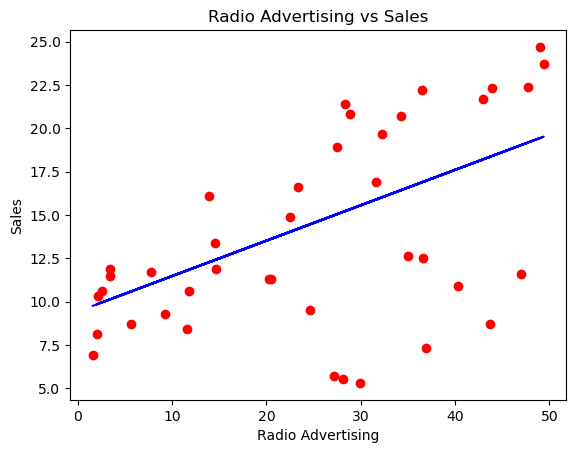

In [100]:
plt.scatter(X_test, y_test, color='red')
plt.plot(X_test, y_pred, color='blue')
plt.title('Radio Advertising vs Sales')
plt.xlabel('Radio Advertising')
plt.ylabel('Sales')
plt.show()

In [127]:
print(np.sqrt(mean_squared_error(y_test, y_pred)))
print(r2_score(y_test, y_pred))
print(mean_absolute_error(y_test, y_pred))

4.8216974799471926
0.2634309396999792
3.9298787572224847


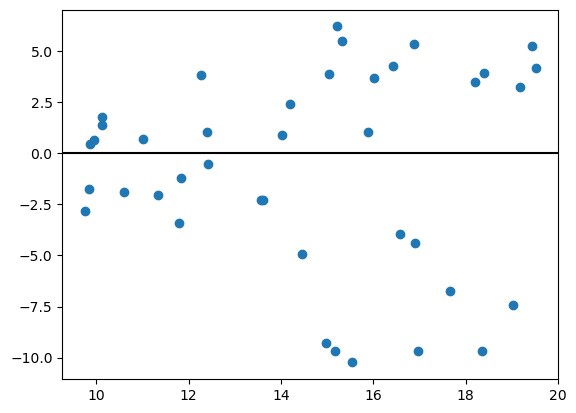

In [102]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color="black")

In [128]:
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB
from sklearn.metrics import mean_absolute_error

row = pd.DataFrame([{
    "project": "p1_advertising",
    "model": "slr_radio",
    "params": {"feature": "radio", "test_size": 0.2, "random_state": 42},
    "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "mae": float(mean_absolute_error(y_test, y_pred)),
    "r2": float(r2_score(y_test, y_pred)),
    "slope": float(model.coef_[0]),
    "run_at": datetime.now(),
}])
row.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

## Newspaper

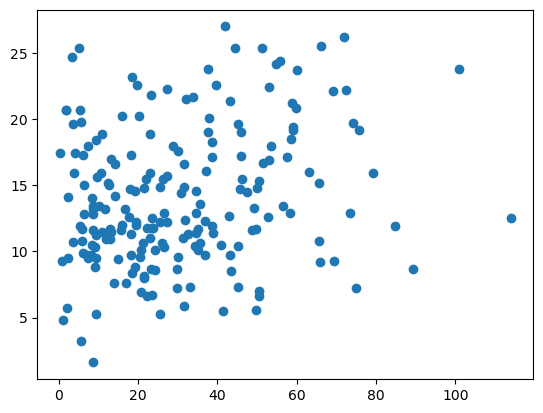

In [104]:
plt.scatter(adv['newspaper'], adv['sales'])

In [140]:
X = adv[['newspaper']]
y = adv['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [141]:
print(model.intercept_)
print(model.coef_)

12.31054833403927
[0.0597567]


In [131]:
y_pred = model.predict(X_test)

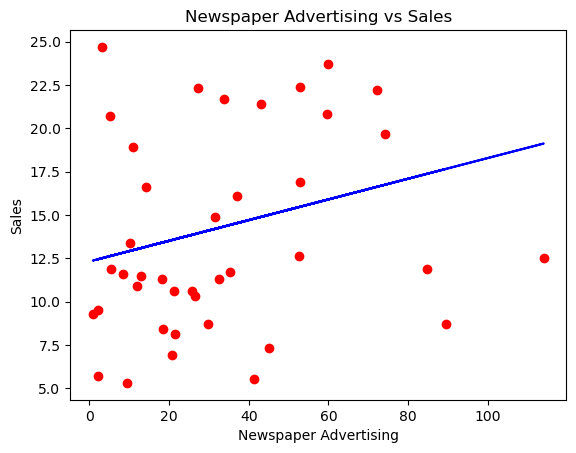

In [107]:
plt.scatter(X_test, y_test, color='red')
plt.plot(X_test, y_pred, color='blue')
plt.title('Newspaper Advertising vs Sales')
plt.xlabel('Newspaper Advertising')
plt.ylabel('Sales')
plt.show()

In [132]:
print(np.sqrt(mean_squared_error(y_test, y_pred)))
print(r2_score(y_test, y_pred))
print(mean_absolute_error(y_test, y_pred))

5.533600454969853
0.029871749149522397
4.782194119516899


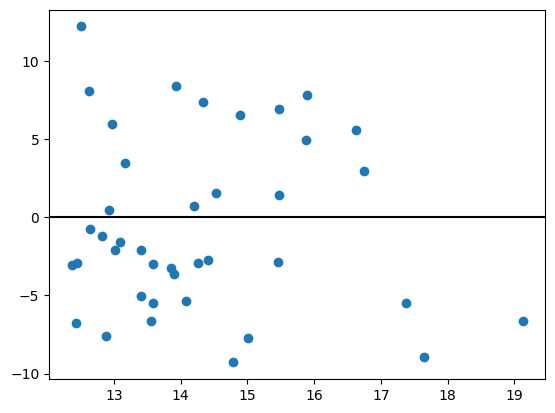

In [109]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color="black")

In [133]:
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB
from sklearn.metrics import mean_absolute_error

row = pd.DataFrame([{
    "project": "p1_advertising",
    "model": "slr_newspaper",
    "params": {"feature": "newspaper", "test_size": 0.2, "random_state": 42},
    "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "mae": float(mean_absolute_error(y_test, y_pred)),
    "r2": float(r2_score(y_test, y_pred)),
    "slope": float(model.coef_[0]),
    "run_at": datetime.now(),
}])
row.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

In [135]:
pd.read_sql("select model, r2, rmse, slope from model_results", engine)

,model,r2,rmse,slope
0,slr_TV,0.676695,3.194472,0.046530
1,slr_radio,0.263431,4.821697,0.204407
2,slr_newspaper,0.029872,5.533600,0.059757
